<a href="https://colab.research.google.com/github/Aero1th/LASAY_SY.26-27_CCADMACL_EXERCISES/blob/main/LASAY.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression


# Downloads the dataset from Kaggle automatically (no API key needed)
datasetpath = kagglehub.dataset_download("parulpandey/palmer-archipelago-antarctica-penguin-data")
dataseturl = glob.glob(os.path.join(datasetpath, "**", "penguins_size.csv"), recursive=True)[0]

Using Colab cache for faster access to the 'palmer-archipelago-antarctica-penguin-data' dataset.


1. Load the Dataset

Run the cell below to load the data. Each row is one penguin.

In [2]:
df = pd.read_csv(dataseturl)
df.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


2. Prepare the Data

The cell below keeps only the Adelie and Chinstrap penguins, removes rows with missing values, and prepares these columns:

In [3]:
penguins = df[df["species"].isin(["Adelie", "Chinstrap"]) & df["sex"].isin(["MALE", "FEMALE"])].dropna()

data = pd.DataFrame({
    "BillLength":    penguins["culmen_length_mm"],
    "BillDepth":     penguins["culmen_depth_mm"],
    "FlipperLength": penguins["flipper_length_mm"],
    "BodyMass":      penguins["body_mass_g"] / 1000,                    # grams -> kg
    "Sex":           (penguins["sex"] == "MALE").astype(int),          # female = 0, male = 1
    "Species":       (penguins["species"] == "Chinstrap").astype(int), # 0 = Adelie, 1 = Chinstrap
})

features = ["BillLength", "BillDepth", "FlipperLength", "BodyMass", "Sex"]

train, test = train_test_split(data, test_size=0.2, stratify=data["Species"], random_state=42)

X_train, y_train = train[features], train["Species"]
X_test,  y_test  = test[features],  test["Species"]

# ---- For the visualizations ----
# Grid of (BillLength, BillDepth) points that covers the whole plot
xx, yy = np.meshgrid(np.linspace(30, 60, 300), np.linspace(14, 23, 300))
grid = pd.DataFrame({"BillLength": xx.ravel(), "BillDepth": yy.ravel()})

colors = {0: "#1f8bb5", 1: "#d1495b"}
labels = {0: "Adelie", 1: "Chinstrap"}

print("Train:", X_train.shape, " Test:", X_test.shape)
X_train.head()

Train: (171, 5)  Test: (43, 5)


,BillLength,BillDepth,FlipperLength,BodyMass,Sex
179,49.5,19.0,200.0,3.800,1
134,38.1,17.6,187.0,3.425,0
41,40.8,18.4,195.0,3.900,1
29,40.5,18.9,180.0,3.950,1
44,37.0,16.9,185.0,3.000,0


PART 1 — GENERATIVE:
Naive Bayes (25 pts)

A generative model learns how each group's data is spread out: what Adelie penguins usually look like, and what Chinstrap penguins usually look like. From this it gets the joint probability of the features and the label, then uses Bayes' rule to classify.

We will use GaussianNB, a Naive Bayes model for numeric features.

3. Train the Model (8 pts)

Create a GaussianNB() model and name it nb. (4 pts)

Train it on X_train and y_train. (4 pts)

Hint: model.fit(X, y)

In [4]:
nb = GaussianNB()
nb.fit(X_train, y_train)

GaussianNB()

4. Predict and Evaluate (7 pts)

Predict the labels of X_test and save them as pred_nb. (3 pts)

Compute the accuracy and save it as acc_nb. Print it. (4 pts)

Hint: model.predict(X) and accuracy_score(y_true, y_pred)



In [13]:
pred_nb = nb.predict(X_test)
acc_nb = accuracy_score(y_test, pred_nb)
print("Naive Bayes Test Accuracy:", round(acc_nb * 100, 2), "%","|", round(acc_nb, 4))

Naive Bayes Test Accuracy: 95.35 % | 0.9535


5. Visualize the Generative Model (10 pts)
Show the shape of each group (Adelie / Chinstrap) that Naive Bayes learned.

A plot only has 2 axes, but nb uses 5 features. So for the plot, train a small copy of the model that uses only BillLength (x-axis) and BillDepth (y-axis).

Create another GaussianNB() named nb_2d and train it on X_train[["BillLength", "BillDepth"]] and y_train. (2 pts)

Compute the joint probability of every point in grid using nb_2d and save it as joint_nb. (2 pts)

For each group, draw a filled shape and an outline using joint_nb, in that group's color. (3 pts)

On the same plot, draw the training penguins as dots, using colors and labels. Add axis labels, a title and a legend. (3 pts)

Hints:

np.exp(nb_2d.predict_joint_log_proba(grid)) gives the joint probability. Column 0 = Adelie, column 1 = Chinstrap.

For each group k: z = joint_nb[:, k].reshape(xx.shape), then
ax.contourf(xx, yy, z, levels=[z.max() * 0.1, z.max()], colors=colors[k], alpha=0.25)
ax.contour(xx, yy, z, levels=[z.max() * 0.1], colors=colors[k], linewidths=2)

  ax.scatter(x, y, c=colors[k], edgecolors="white", s=55, label=labels[k])

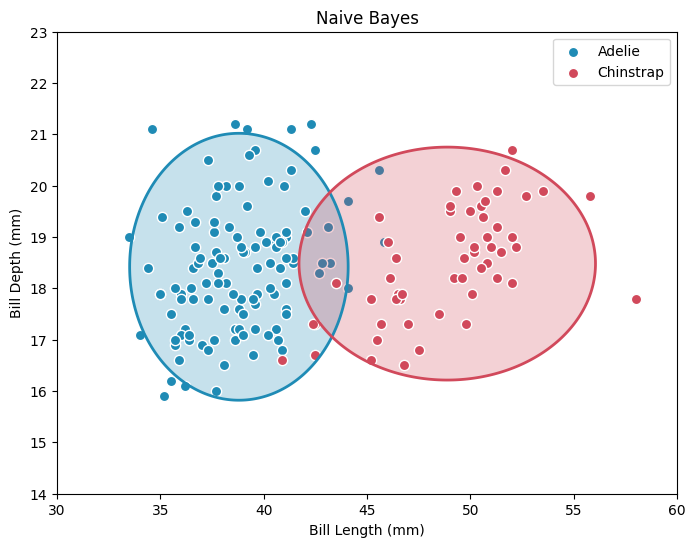

In [24]:
nb_2d = GaussianNB()
nb_2d.fit(X_train[["BillLength", "BillDepth"]], y_train)

joint_nb = np.exp(nb_2d.predict_joint_log_proba(grid))

fig, ax = plt.subplots(figsize=(8, 6))
for k in [0, 1]:
    z = joint_nb[:, k].reshape(xx.shape)
    ax.contourf(xx, yy, z, levels=[z.max() * 0.1, z.max()], colors=colors[k], alpha=0.25)
    ax.contour(xx, yy, z, levels=[z.max() * 0.1], colors=colors[k], linewidths=2)

    ax.scatter(X_train.loc[y_train == k, "BillLength"], X_train.loc[y_train == k, "BillDepth"],
               c=colors[k], edgecolors="white", s=55, label=labels[k])

ax.set_xlabel("Bill Length (mm)")
ax.set_ylabel("Bill Depth (mm)")
ax.set_title("Naive Bayes")
ax.legend()
plt.show()

PART 2 — DISCRIMINATIVE: Logistic Regression (25 pts)

A discriminative model does not learn how each group's data is spread out. It learns the conditional probability of the species given the features directly, and draws a decision boundary between the groups.

We will use LogisticRegression.

6. Train the Model (8 pts)

Create a LogisticRegression(max_iter=1000) model and name it logreg. (4 pts)

Train it on X_train and y_train. (4 pts)

In [25]:
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

7. Predict and Evaluate (7 pts)

Predict the labels of X_test and save them as pred_lr. (3 pts)

Compute the accuracy and save it as acc_lr. Print it. (4 pts)

In [27]:
pred_lr = logreg.predict(X_test)
acc_lr = accuracy_score(y_test, pred_lr)
print("Logistic Regression test accuracy:", round(acc_lr, 4))

Logistic Regression test accuracy: 1.0


8. Visualize the Discriminative Model (10 pts)

Show the decision boundary that Logistic Regression learned between Adelie and Chinstrap.

Same as Section 5: for the plot, train a small copy of the model that uses only BillLength and BillDepth.

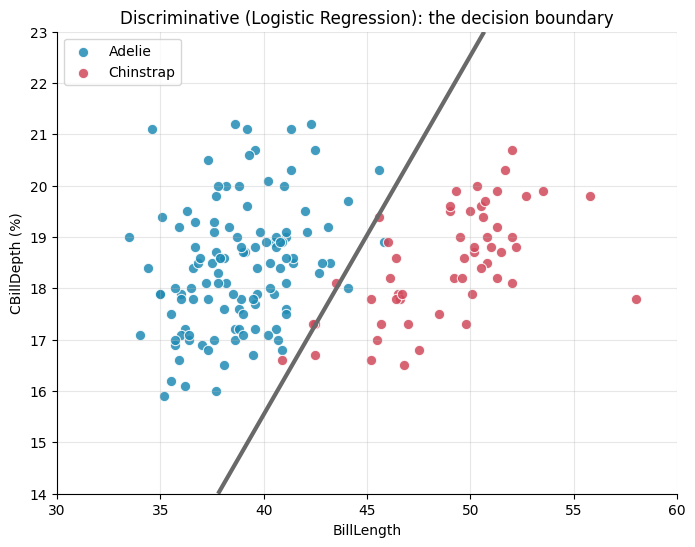

In [32]:
logreg_2d = LogisticRegression(max_iter=1000)
logreg_2d.fit(X_train[["BillLength", "BillDepth"]], y_train)

cond_lr = logreg_2d.predict_proba(grid)[:, 1]

fig, ax = plt.subplots(figsize=(8, 6))

for k in [0, 1]:
    ax.scatter(X_train.loc[y_train == k, "BillLength"], X_train.loc[y_train == k, "BillDepth"], c=colors[k], edgecolors="white", linewidths=0.8, s=55, alpha=0.85, label=labels[k])

ax.contour(xx, yy, cond_lr.reshape(xx.shape), levels=[0.5], colors="dimgray", linewidths=3)

ax.set_xlabel("BillLength")
ax.set_ylabel("CBillDepth (%)")
ax.set_title("Discriminative (Logistic Regression): the decision boundary")
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left")
plt.show()

9. Compare the Models

Run the cell below to compare your two models.

,Model,Type,Learns,Test Accuracy
0,Naive Bayes (GaussianNB),Generative,Joint probability,0.9535
1,Logistic Regression,Discriminative,Conditional probability,1.0000


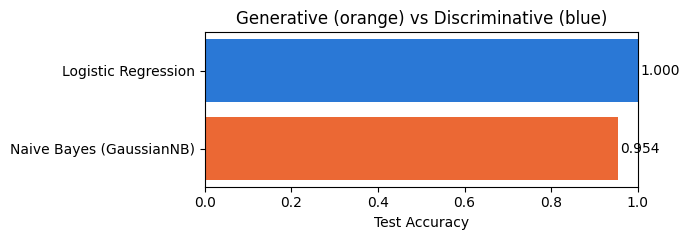

In [33]:
comparison = pd.DataFrame({
    "Model": ["Naive Bayes (GaussianNB)", "Logistic Regression"],
    "Type":  ["Generative", "Discriminative"],
    "Learns": ["Joint probability", "Conditional probability"],
    "Test Accuracy": [acc_nb, acc_lr],
}).round(4)
display(comparison)

bar_colors = comparison["Type"].map({"Generative": "#eb6834", "Discriminative": "#2a78d6"})
plt.figure(figsize=(7, 2.5))
plt.barh(comparison["Model"], comparison["Test Accuracy"], color=bar_colors)
for i, v in enumerate(comparison["Test Accuracy"]):
    plt.text(v + 0.005, i, f"{v:.3f}", va="center")
plt.xlim(0, 1)
plt.xlabel("Test Accuracy")
plt.title("Generative (orange) vs Discriminative (blue)")
plt.tight_layout()
plt.show()